In [1]:
import xarray as xr
import xroms
import xcmocean
import matplotlib.pyplot as plt
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import (
    LinearLR,
    CosineAnnealingLR,
    SequentialLR
)
from neuralop.layers.fno_block import FNOBlocks
import time
from concurrent.futures import ThreadPoolExecutor

In [4]:
def open_pactcs30(year=2010):
    path = "../../../GROUP/pactcs30/pactcs30_" + str(year) + "_avg.zarr"
    # dates on the original ROMS output have the wrong time
    ds = xr.open_zarr(path, decode_times=False)
    # we have to set the units and calendar from 0000-01-01 00:00:00 and 365noleap
    ds['time'].attrs['units'] = "seconds since 1979-01-01 00:00:00"
    ds['time'].attrs['calendar'] = "gregorian"
    ds = xr.decode_cf(ds)  # now, interpret the calendar
    # read in the data with ROMS package - allows for easy plotting
    ds, _ = xroms.roms_dataset(ds, include_3D_metrics=False)
    return ds

def load_pactcs30(timespan=[2010]):
    all_data = [open_pactcs30(year) for year in timespan]
    dataset = xr.concat(all_data, dim='time', data_vars="minimal", coords="minimal").compute()
    mean = get_mean(dataset)
    std = get_std(dataset)

    return dataset, mean, std

def clean_pactcs30(old_dataset, mean, std):
    u_rho = 0.5 * (old_dataset.u.isel(xi_u=slice(0,-1)) + old_dataset.u.isel(xi_u=slice(1, None)))
    u_rho["xi_u"] = u_rho["xi_u"] + 1
    u_rho = u_rho.rename({"xi_u" : "xi_rho"})

    v_rho = 0.5 * (old_dataset.v.isel(eta_v=slice(0,-1)) + old_dataset.v.isel(eta_v=slice(1, None)))
    v_rho["eta_v"] = v_rho["eta_v"] + 1
    v_rho = v_rho.rename({"eta_v" : "eta_rho"})
    
    new = xr.Dataset({
        "u" : u_rho.squeeze("s_rho"),
        "v" : v_rho.squeeze("s_rho"),
        "w" : old_dataset["w"].squeeze("s_rho"),
        "temp" : old_dataset["temp"].squeeze("s_rho"),
        "salt" : old_dataset["salt"].squeeze("s_rho"),
        "zeta" : old_dataset["zeta"],
        "DIC" : old_dataset["DIC"].squeeze("s_rho"),
        "PCO2OC" : old_dataset["PCO2OC"],
        "mask_rho" : old_dataset["mask_rho"]
    })

    new.pad(
        u=1,
        v=1,
    )

    new = new.fillna(0)

    data_vars = list(new.data_vars)
    data_vars.remove("mask_rho")
    
    for v in data_vars:
        new[v] = (new[v] - mean[v]) / std[v]
    
    return new

def get_mean(dataset):
    mean = dict()
    data_vars = ["u", "v", "w", "temp", "salt", "zeta", "DIC", "PCO2OC"]

    for v in data_vars:
        mean[v] = np.nanmean(dataset[v])

    return mean

def get_std(dataset):
    std = dict()
    data_vars = ["u", "v", "w", "temp", "salt", "zeta", "DIC", "PCO2OC"]

    for v in data_vars:
        std[v] = np.nanstd(dataset[v])

    return std
        
def tensor_to_dataset(tensor, mean, std, mask, eta_rho, xi_rho, lat_rho, lon_rho):
    tensor_data = tensor.detach().numpy()
    
    data_vars = ["u", "v", "w", "temp", "salt", "zeta", "DIC", "PCO2OC", "mask_rho"]
    data_array = []

    for t in tensor_data:
        data_array.append(
            xr.DataArray(
                data=t,
                dims=["eta_rho", "xi_rho"],
                coords={
                    "eta_rho": eta_rho,
                    "xi_rho": xi_rho,
                },
            )
        )

    data_array.append(mask)
    dataset = xr.Dataset(dict(zip(data_vars, data_array)))

    data_vars.remove("mask_rho")
    for v in data_vars:
        dataset[v] = (dataset[v] * std[v]) + mean[v]
        dataset[v] =  dataset[v].where(dataset["mask_rho"] == 1)
    
    dataset = dataset.assign_coords(
        lat_rho = lat_rho,
        lon_rho = lon_rho,
    )

    return dataset

def plot_dataset(dataset, var=["temp"]):
    for v in var:
        dataset[v].cf.plot(
            x="longitude",
            y="latitude",
            robust=True,
            cmap="cmo.thermal",
        )
        plt.title(f"{v}")
        plt.show()

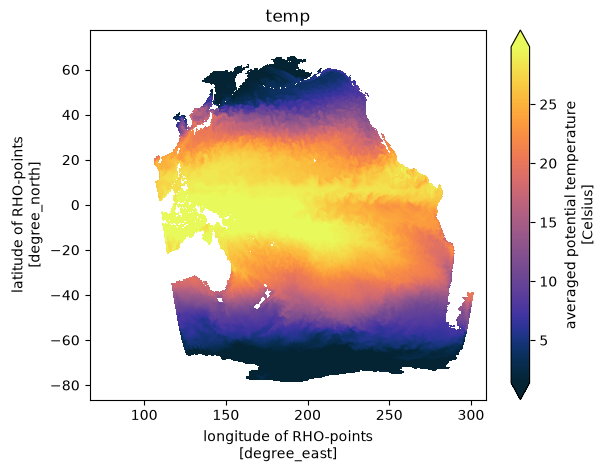

NameError: name 'Pactcs30Dataset' is not defined

In [5]:
dataset, mean, std = load_pactcs30()
plot_dataset(dataset.isel(time=0))
dataset = clean_pactcs30(dataset, mean, std)

dl = DataLoader(Pactcs30Dataset(dataset), batch_size=batch_size, shuffle=False)
f, _ = next(iter(dl))

dataset = tensor_to_dataset(f[0, 2:], mean, std, dataset.mask_rho, dataset.eta_rho, dataset.xi_rho, dataset.lat_rho, dataset.lon_rho)
plot_dataset(dataset)

In [6]:
class Pactcs30Dataset(Dataset):
    def __init__(self, dataset):
        self.data = dataset
        self.transform= None
        self.target_transform = None
        self.len = 0
        
        # -1 because last entry has no next simulation step
        self.len = dataset.sizes["time"] - 1
        self.data = [None] * (self.len + 1)
        
        row, col = dataset.sizes["eta_rho"], dataset.sizes["xi_rho"]
        base_time = torch.ones((row, col), dtype=torch.float32)
        
        mask_rho = torch.from_numpy(dataset["mask_rho"].values)
        
        data_vars = list(dataset.data_vars)
        data_vars.remove("mask_rho")

        def store_tensor(idx):
            datapoint = dataset.isel(time=idx)
            time = datapoint.time.dt.dayofyear.values.item() * base_time
            features = [time, mask_rho]

            for var in data_vars:
                features.append(torch.from_numpy(datapoint[var].values))

            self.data[idx] = torch.stack(features)

        jobs = [i for i in range(self.len + 1)]
        
        with ThreadPoolExecutor((os.cpu_count() or 1)) as executor:
            list(executor.map(store_tensor, jobs))
            
    def __len__(self):
        return self.len

    def __getitem__(self, idx):
        feature = self.data[idx]
        label = self.data[idx+1][2:]
        return feature, label

    def get_mean():
        return self.mean

    def get_std():
        return self.std
        

In [126]:
s = time.time()
dataset, mean, std = load_pactcs30()
dataset = clean_pactcs30(dataset, mean, std)
dataloader = DataLoader(Pactcs30Dataset(dataset), batch_size=64, shuffle=True)
e = time.time()

print(e-s)

18.06716251373291


In [148]:
f, l = next(iter(dataloader))
print(f.shape, l.shape)

torch.Size([64, 10, 518, 604]) torch.Size([64, 8, 518, 604])


In [13]:
class Pactcs30Fno(nn.Module):
    def __init__(self):
        super().__init__()
        self.mean = mean
        self.std = std
        self.fno = FNOBlocks(
            in_channels=16,
            out_channels=16,
            n_modes=(16, 16),
            n_layers=4,
        )
        self.lift = nn.Conv2d(10, 16, 1)
        self.proj = nn.Conv2d(16, 8, 1)

    def forward(self, x):
        x = self.lift(x)
        x = self.fno(x)
        x = self.proj(x)
        return x

In [14]:
fno = Pactcs30Fno()

base_lr = 1e-3
min_lr = 1e-6
batch_size = 32
epochs = 5

loss_fn = nn.L1Loss()
optimizer = torch.optim.AdamW(fno.parameters(), lr=base_lr)

total_steps = 100
warmup_steps = 10
decay_steps = total_steps - warmup_steps

warmup_scheduler = LinearLR(
    optimizer,
    start_factor=0.01,
    end_factor=1.0,
    total_iters=warmup_steps
)

cosine_scheduler = CosineAnnealingLR(
    optimizer,
    T_max=decay_steps,
    eta_min=min_lr
)

scheduler = SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[warmup_steps]
)

tr_data, tr_mean, tr_std = load_pactcs30([2010])
te_data, te_mean, te_std = load_pactcs30([2011])

tr_data = clean_pactcs30(tr_data, tr_mean, tr_std)
te_data = clean_pactcs30(te_data, te_mean, te_std)

tr_dataloader = DataLoader(Pactcs30Dataset(tr_data), batch_size=batch_size, shuffle=True)
te_dataloader = DataLoader(Pactcs30Dataset(te_data), batch_size=batch_size, shuffle=True)

epoch: 0
Avg loss: 12.994108 

Avg loss: 11.063273 

<xarray.Dataset> Size: 14MB
Dimensions:   (eta_rho: 518, xi_rho: 604)
Coordinates:
  * eta_rho   (eta_rho) int64 4kB 0 1 2 3 4 5 6 ... 511 512 513 514 515 516 517
  * xi_rho    (xi_rho) int64 5kB 0 1 2 3 4 5 6 7 ... 597 598 599 600 601 602 603
    lat_rho   (eta_rho, xi_rho) float32 1MB 60.35 60.19 60.04 ... 35.92 35.94
    lon_rho   (eta_rho, xi_rho) float32 1MB 66.9 67.32 67.73 ... 251.5 251.6
Data variables:
    u         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    v         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    w         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    temp      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    salt      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    zeta      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    DIC       (eta_rho, xi_rho) float32 1MB nan nan 

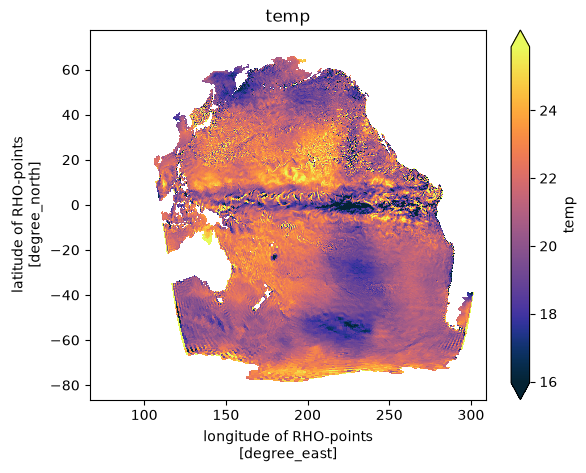

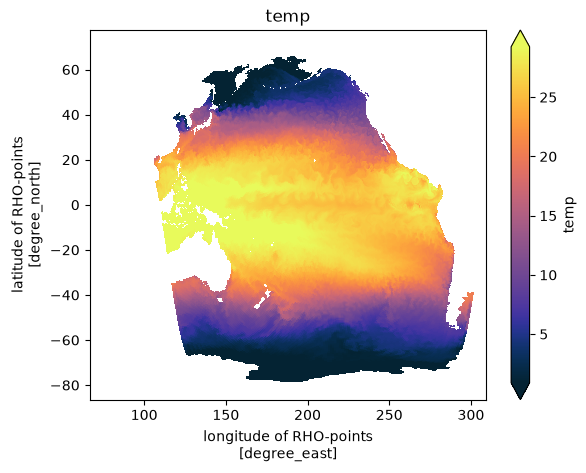

epoch: 1
Avg loss: 9.261842 

Avg loss: 6.944762 

<xarray.Dataset> Size: 14MB
Dimensions:   (eta_rho: 518, xi_rho: 604)
Coordinates:
  * eta_rho   (eta_rho) int64 4kB 0 1 2 3 4 5 6 ... 511 512 513 514 515 516 517
  * xi_rho    (xi_rho) int64 5kB 0 1 2 3 4 5 6 7 ... 597 598 599 600 601 602 603
    lat_rho   (eta_rho, xi_rho) float32 1MB 60.35 60.19 60.04 ... 35.92 35.94
    lon_rho   (eta_rho, xi_rho) float32 1MB 66.9 67.32 67.73 ... 251.5 251.6
Data variables:
    u         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    v         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    w         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    temp      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    salt      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    zeta      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    DIC       (eta_rho, xi_rho) float32 1MB nan nan na

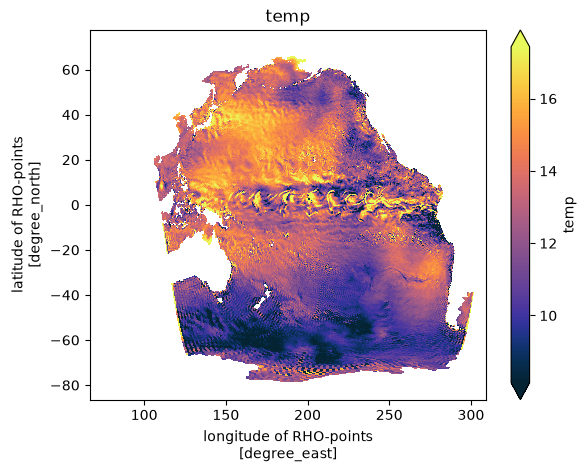

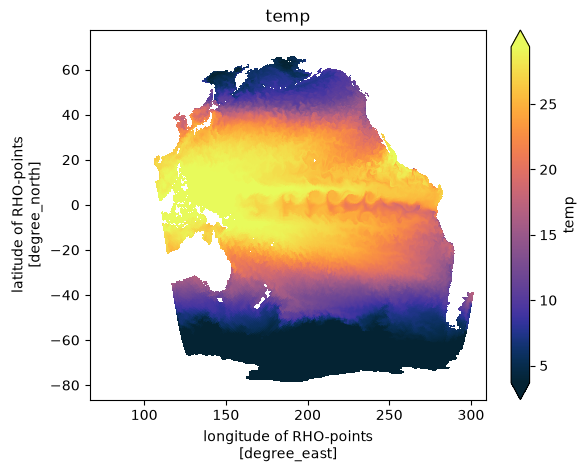

epoch: 2
Avg loss: 5.076871 

Avg loss: 2.976893 

<xarray.Dataset> Size: 14MB
Dimensions:   (eta_rho: 518, xi_rho: 604)
Coordinates:
  * eta_rho   (eta_rho) int64 4kB 0 1 2 3 4 5 6 ... 511 512 513 514 515 516 517
  * xi_rho    (xi_rho) int64 5kB 0 1 2 3 4 5 6 7 ... 597 598 599 600 601 602 603
    lat_rho   (eta_rho, xi_rho) float32 1MB 60.35 60.19 60.04 ... 35.92 35.94
    lon_rho   (eta_rho, xi_rho) float32 1MB 66.9 67.32 67.73 ... 251.5 251.6
Data variables:
    u         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    v         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    w         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    temp      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    salt      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    zeta      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    DIC       (eta_rho, xi_rho) float32 1MB nan nan na

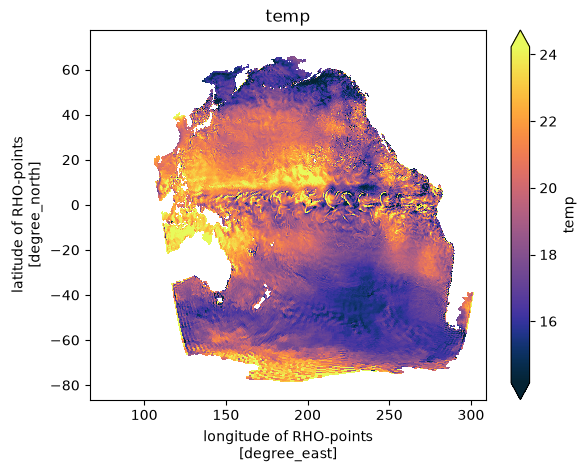

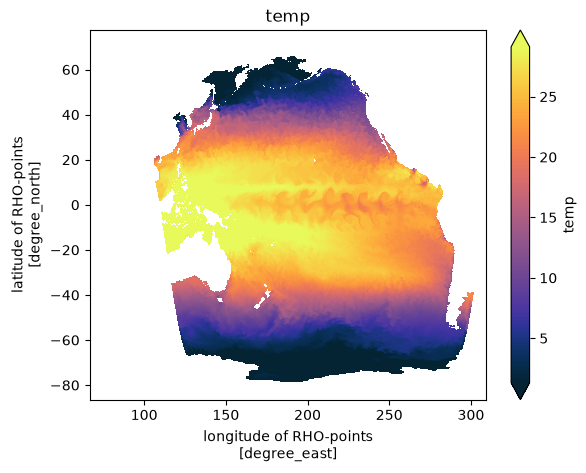

epoch: 3
Avg loss: 2.105986 

Avg loss: 1.731639 

<xarray.Dataset> Size: 14MB
Dimensions:   (eta_rho: 518, xi_rho: 604)
Coordinates:
  * eta_rho   (eta_rho) int64 4kB 0 1 2 3 4 5 6 ... 511 512 513 514 515 516 517
  * xi_rho    (xi_rho) int64 5kB 0 1 2 3 4 5 6 7 ... 597 598 599 600 601 602 603
    lat_rho   (eta_rho, xi_rho) float32 1MB 60.35 60.19 60.04 ... 35.92 35.94
    lon_rho   (eta_rho, xi_rho) float32 1MB 66.9 67.32 67.73 ... 251.5 251.6
Data variables:
    u         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    v         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    w         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    temp      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    salt      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    zeta      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    DIC       (eta_rho, xi_rho) float32 1MB nan nan na

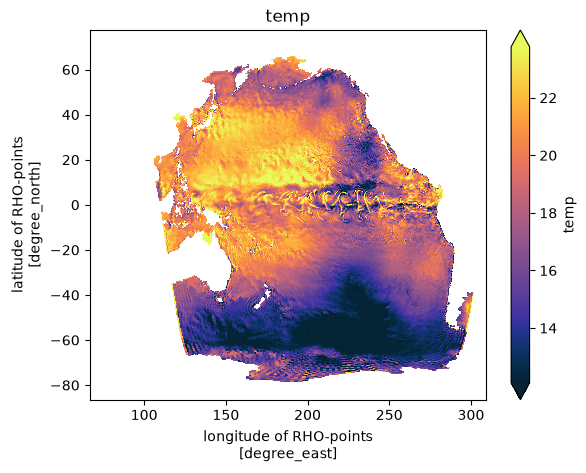

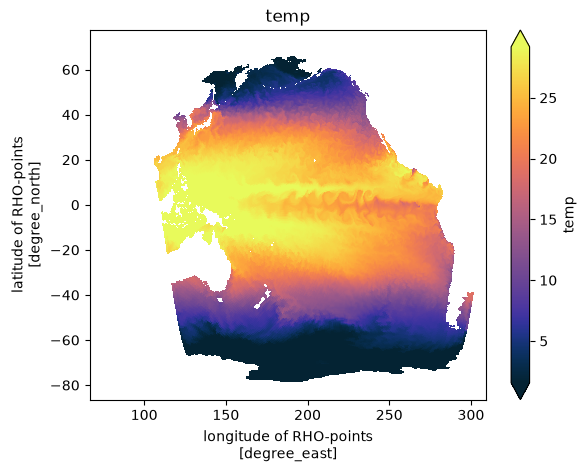

epoch: 4
Avg loss: 1.441831 

Avg loss: 1.122828 

<xarray.Dataset> Size: 14MB
Dimensions:   (eta_rho: 518, xi_rho: 604)
Coordinates:
  * eta_rho   (eta_rho) int64 4kB 0 1 2 3 4 5 6 ... 511 512 513 514 515 516 517
  * xi_rho    (xi_rho) int64 5kB 0 1 2 3 4 5 6 7 ... 597 598 599 600 601 602 603
    lat_rho   (eta_rho, xi_rho) float32 1MB 60.35 60.19 60.04 ... 35.92 35.94
    lon_rho   (eta_rho, xi_rho) float32 1MB 66.9 67.32 67.73 ... 251.5 251.6
Data variables:
    u         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    v         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    w         (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    temp      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    salt      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    zeta      (eta_rho, xi_rho) float32 1MB nan nan nan nan ... nan nan nan nan
    DIC       (eta_rho, xi_rho) float32 1MB nan nan na

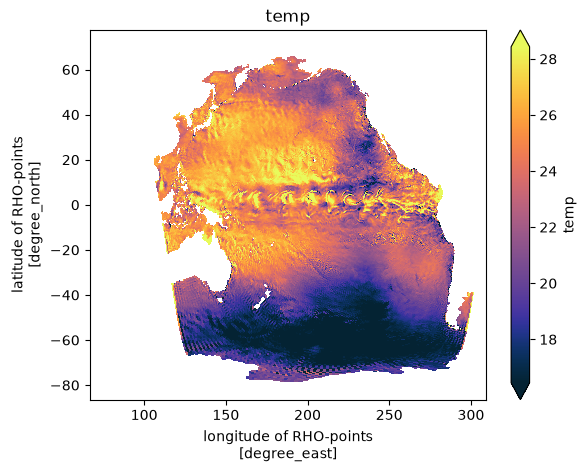

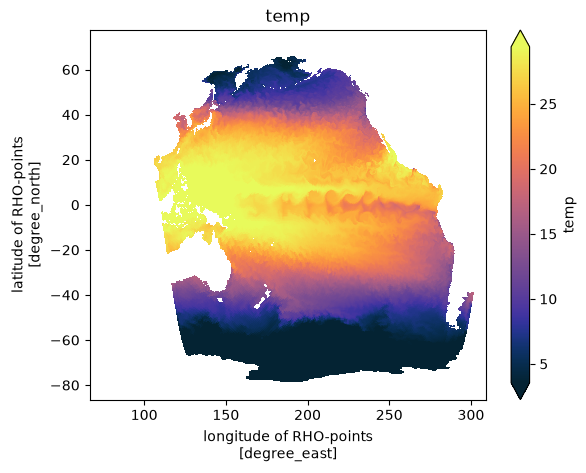

In [15]:
def train(dataloader, model, loss_fn, optimizer, mask):
    num_batches = len(dataloader)
    model.train()
    train_loss = 0
    
    for batch, (X, y) in enumerate(dataloader):
        pred = fno(X)
        v_mask = mask.expand_as(pred)
        
        loss = loss_fn(pred[v_mask], y[v_mask])
        loss.backward()
        
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

        train_loss += loss.item()

    train_loss /= num_batches
    print(f"Avg loss: {train_loss:>8f} \n")

def test(dataloader, model, loss_fn, mask):
    model.eval()
    num_batches = len(dataloader)
    test_loss = 0

    with torch.no_grad():
        for X, y in dataloader:
            pred = model(X)
            v_mask = mask.expand_as(pred)
            
            test_loss += loss_fn(pred[v_mask], y[v_mask]).item()

    test_loss /= num_batches
    print(f"Avg loss: {test_loss:>8f} \n")
    
    feature, label = next(iter(dataloader))
    pred = model(feature)
    pred_dataset = tensor_to_dataset(pred[0], te_mean, te_std, te_data.mask_rho, te_data.eta_rho, te_data.xi_rho, te_data.lat_rho, te_data.lon_rho)
    label_dataset = tensor_to_dataset(label[0], te_mean, te_std, te_data.mask_rho, te_data.eta_rho, te_data.xi_rho, te_data.lat_rho, te_data.lon_rho)

    print(pred_dataset)
    print("")
    print(label_dataset)
    print("")
    
    plot_dataset(pred_dataset)
    plot_dataset(label_dataset)

mask = torch.from_numpy(tr_data.mask_rho.values).bool()

for i in range(epochs):
    print(f"epoch: {i}")
    train(tr_dataloader, fno, loss_fn, optimizer, mask)
    test(te_dataloader, fno, loss_fn, mask)